<a href="https://colab.research.google.com/github/sonyxoxo/ipd/blob/main/06_%D0%BF%D1%80%D0%BE%D0%B2%D0%B5%D1%80%D0%BA%D0%B0_%D0%BD%D0%B0%D1%83%D1%87%D0%BD%D1%8B%D1%85_%D0%B3%D0%B8%D0%BF%D0%BE%D1%82%D0%B5%D0%B7_(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/sonyxoxo/ipd/blob/main/%D0%BD%D0%BE%D1%83%D1%82%D0%B1%D1%83%D0%BA%D0%B8%20python/06_%D0%BF%D1%80%D0%BE%D0%B2%D0%B5%D1%80%D0%BA%D0%B0_%D0%BD%D0%B0%D1%83%D1%87%D0%BD%D1%8B%D1%85_%D0%B3%D0%B8%D0%BF%D0%BE%D1%82%D0%B5%D0%B7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Этап 6 — научные гипотезы: проверка v2

**Цель:** определить, как отличаются профили выбранных месяцев и насколько результаты меняются при удалении и обработке минутных измерений.

**Источник:** UCI Individual Household Electric Power Consumption, активная мощность `Global_active_power` в **кВт**. Субсчётчики имеют единицы **Вт·ч на минуту**. Исходные измерения никогда не перезаписываются.

**Важно:** в раннем эксперименте 6-го этапа расчёты выполнялись непосредственно в ячейках. Теперь алгоритмы вынесены в тестируемый модуль [`ipd_science.py`](../ipd_science.py). Представленные ранее численные результаты необходимо получить заново; они не переносятся автоматически в методику v2.

**Порядок:** открытие данных → H1 (полные сутки и блоки) → H2 (маски пропусков) → H3 (сравнение обработки) → физические проверки и контрольные суммы. Выводы являются исследовательскими, не причинными.

## 6.1. Загрузка и фиксированные параметры

Открываем локальный репозиторий. В Colab, если его ещё нет, клонируем только один раз. Google Drive, ручные загрузки и изменения исходного ZIP не требуются. Выводим путь источника и число строк.

In [ ]:
from pathlib import Path
import sys
import subprocess
import pandas as pd
from IPython.display import display, Image

root = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "ipd_analysis.py").is_file()), None)
if root is None:
    root = Path("/content/ipd")
    if not (root / "ipd_analysis.py").exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/sonyxoxo/ipd.git", str(root)], check=True)
sys.path.insert(0, str(root))

from ipd_analysis import choose_source, load_measurements, regular_minutes, result_folder
from ipd_science import run_science, write_manifest, source_quality_report
from scripts.verify_results import verify_directory

source = choose_source()  # при нескольких источниках укажите путь явно
measurements = load_measurements(source)
minutes = regular_minutes(measurements)
out = result_folder(source) / "этап_06_v2"
out.mkdir(parents=True, exist_ok=True)
source_quality_report(measurements, out)
print("Источник:", source)
print("Число минут исходного файла:", len(measurements))
print("Недействительных/отсутствующих значений активной мощности:", int(minutes.Global_active_power.isna().sum()))

## 6.2. Выполнение научных экспериментов

**H1:** сутки — единица анализа, сравниваются нормированные 24-часовые профили. Статистика междугрупповых расстояний для непересекающихся блоков:

$$T=\sum_m n_m\left\|\overline{\boldsymbol{x}}_m-\overline{\boldsymbol{x}}\right\|^2.$$

Повторяем перестановки по блокам 3, 5 и 7 суток, корректируем три p-value по Холму **внутри каждого размера блока**. Перестановочная обменность блоков не гарантирована, а бутстреп-интервалы могут быть нестабильны при малом числе блоков. В таблице отдельно показаны исключённые сутки и число блоков.

**H2:** сравниваем случайные, непрерывные и вечерние исключения при 1/5/10/20%, сообщаем MAE и долю определённых точек профиля.

**H3:** при 10% пропусков сравниваем методы на **одинаковых масках**, в том числе на общей области определённости. Дополнительные серии пропусков длиной 1/5/15/30/60/120 минут проверяют пороги интерполяции. Интерполяция не пересекает полуночную границу и не экстраполирует крайние точки.

**Предостережение:** снижение MAE среднего профиля не доказывает точности восстановления индивидуальных минут! Для них есть отдельная метрика `imputed_mae_kw`.

In [2]:
# Все фиксированные генераторы, методы и параметры определены в ipd_science.py.
report = run_science(minutes, out)
print("Статус:")
for key, value in report.items():
    print(key, "→", value)
print("Папка результатов:", out)

Статус:
h1 → {'status': 'ok', 'months': ['2008-01', '2008-04', '2008-07', '2008-09'], 'tests': 9, 'interpretation': 'Exploratory permutation p-values; exchangeability not established'}
control_start → 2008-09-01
control_end → 2008-09-30
h2 → ok
h3 → ok
scientific_limitations → ['one household', 'comparison periods not proof of seasonality', 'permutation exchangeability not verified', 'few independent bootstrap blocks', 'missing-at-random simulation not validation of real missingness', 'MAE on variable support must be accompanied by coverage and common-support MAE']
Папка результатов: /content/ipd/результаты/household_power_consumption-b916e64b/этап_06_v2


## 6.3. Проверка гипотезы H1

`06_h1_days.csv` показывает количество полных и исключённых суток. `p_holm` оценивает эксплораторную статистическую различимость. `n_blocks_total` и `blocks_by_month` показывают фактический объём исходной информации. Цветные интервалы на рисунке — межквартильные диапазоны между сутками, **не доверительные интервалы**.


 06_h1_days.csv


,month,calendar_days,present_days,complete_days,excluded_days
0,2008-01,31,31,30,1
1,2008-04,30,30,30,0
2,2008-07,31,31,30,1
3,2008-09,30,30,30,0



 06_h1_tests.csv


,feature,block_days,p_value,p_holm,n_blocks_total,blocks_by_month,permutations
0,shape,3,0.001,0.003,40,"{""2008-01"": 10, ""2008-04"": 10, ""2008-07"": 10, ...",999
1,amplitude,3,0.001,0.003,40,"{""2008-01"": 10, ""2008-04"": 10, ""2008-07"": 10, ...",999
2,peak_hour_circular,3,0.094,0.094,40,"{""2008-01"": 10, ""2008-04"": 10, ""2008-07"": 10, ...",999
3,shape,5,0.001,0.003,22,"{""2008-01"": 5, ""2008-04"": 6, ""2008-07"": 5, ""20...",999
4,amplitude,5,0.002,0.004,22,"{""2008-01"": 5, ""2008-04"": 6, ""2008-07"": 5, ""20...",999
5,peak_hour_circular,5,0.168,0.168,22,"{""2008-01"": 5, ""2008-04"": 6, ""2008-07"": 5, ""20...",999
6,shape,7,0.003,0.009,14,"{""2008-01"": 3, ""2008-04"": 4, ""2008-07"": 3, ""20...",999
7,amplitude,7,0.029,0.058,14,"{""2008-01"": 3, ""2008-04"": 4, ""2008-07"": 3, ""20...",999
8,peak_hour_circular,7,0.253,0.253,14,"{""2008-01"": 3, ""2008-04"": 4, ""2008-07"": 3, ""20...",999



 06_h1_effect.csv


,first,second,difference_kw,ci_low_kw,ci_high_kw,n_blocks_first,n_blocks_second,bootstrap_repetitions,warning_small_n
0,2008-01,2008-07,0.657178,0.546836,0.775408,5,5,999,True



 06_h1_weekday_weekend.csv


,month,type,days,mean_kw
0,2008-01,weekday,23,1.403094
1,2008-01,weekend,7,1.569173
2,2008-04,weekday,22,1.059134
3,2008-04,weekend,8,1.272276
4,2008-07,weekday,23,0.766064
5,2008-07,weekend,7,0.878138
6,2008-09,weekday,22,0.931900
7,2008-09,weekend,8,1.141077


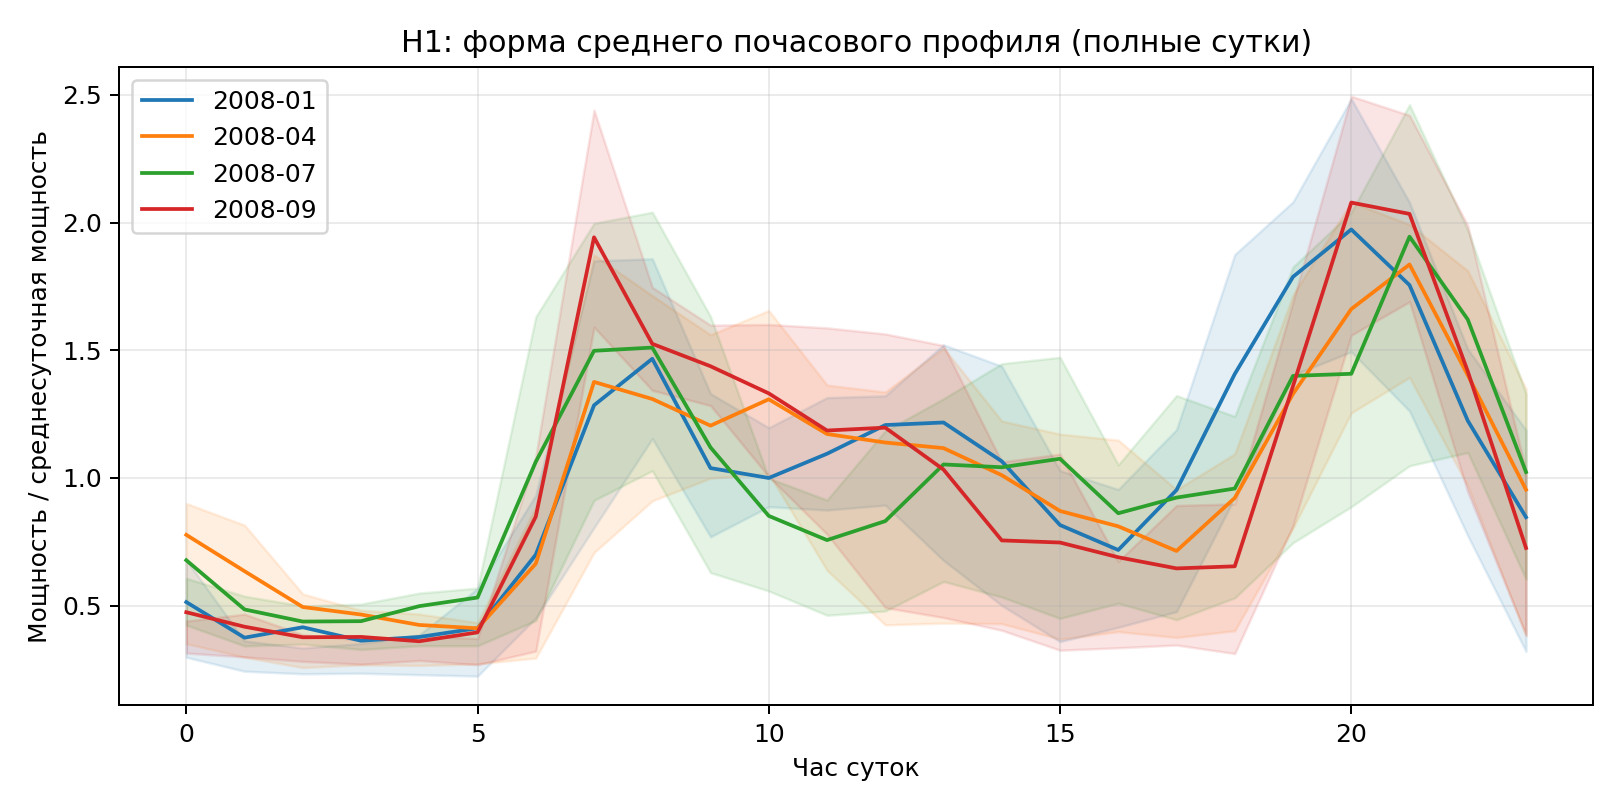

In [3]:
for filename in ("06_h1_days.csv", "06_h1_tests.csv", "06_h1_effect.csv", "06_h1_weekday_weekend.csv"):
    path = out / filename
    if path.exists():
        print("\n", filename)
        display(pd.read_csv(path, sep=";"))
if (out / "06_h1_profiles.png").exists():
    display(Image(filename=str(out / "06_h1_profiles.png")))

## 6.4. Проверка H2

`mean_mae_kw` — ошибка среднего профиля **только** на доступных позициях; `mean_coverage_pct` всегда указывается рядом. `p025_mae_kw` и `p975_mae_kw` — эмпирические квантили сценариев, не доверительный интервал точности неизвестных измерений.

,fraction,scenario,experiments,valid,mean_mae_kw,mean_common_mae_kw,mean_rmse_kw,mean_coverage_pct,mean_energy_bias_pct,mean_imputed_mae_kw,mean_imputed_count,mean_imputed_coverage_pct,p025_mae_kw,p975_mae_kw
0,0.01,continuous,100,100,0.005259,0.005259,0.013620,100.000000,0.017139,NaN,0.0,NaN,0.002386,0.010711
1,0.01,evening,100,100,0.005927,0.005927,0.019170,100.000000,0.000904,NaN,0.0,NaN,0.005304,0.006522
2,0.01,random,100,100,0.005067,0.005067,0.014842,100.000000,-0.002436,NaN,0.0,NaN,0.004586,0.005679
3,0.05,continuous,100,100,0.022637,0.022637,0.032801,100.000000,0.003311,NaN,0.0,NaN,0.016596,0.033397
4,0.05,evening,100,100,0.017965,0.017965,0.047151,100.000000,-0.006808,NaN,0.0,NaN,0.016568,0.019408
5,0.05,random,100,100,0.020572,0.020572,0.034364,100.000000,0.002868,NaN,0.0,NaN,0.019351,0.021976
6,0.10,continuous,100,100,0.034780,0.034780,0.047042,100.000000,-0.015009,NaN,0.0,NaN,0.029630,0.041171
7,0.10,evening,100,100,0.029614,0.029614,0.076812,100.000000,0.027939,NaN,0.0,NaN,0.027263,0.031660
8,0.10,random,100,100,0.033871,0.033871,0.049945,100.000000,-0.012236,NaN,0.0,NaN,0.032488,0.035401
9,0.20,continuous,100,100,0.051396,0.051396,0.069957,100.000000,0.079509,NaN,0.0,NaN,0.044661,0.057959


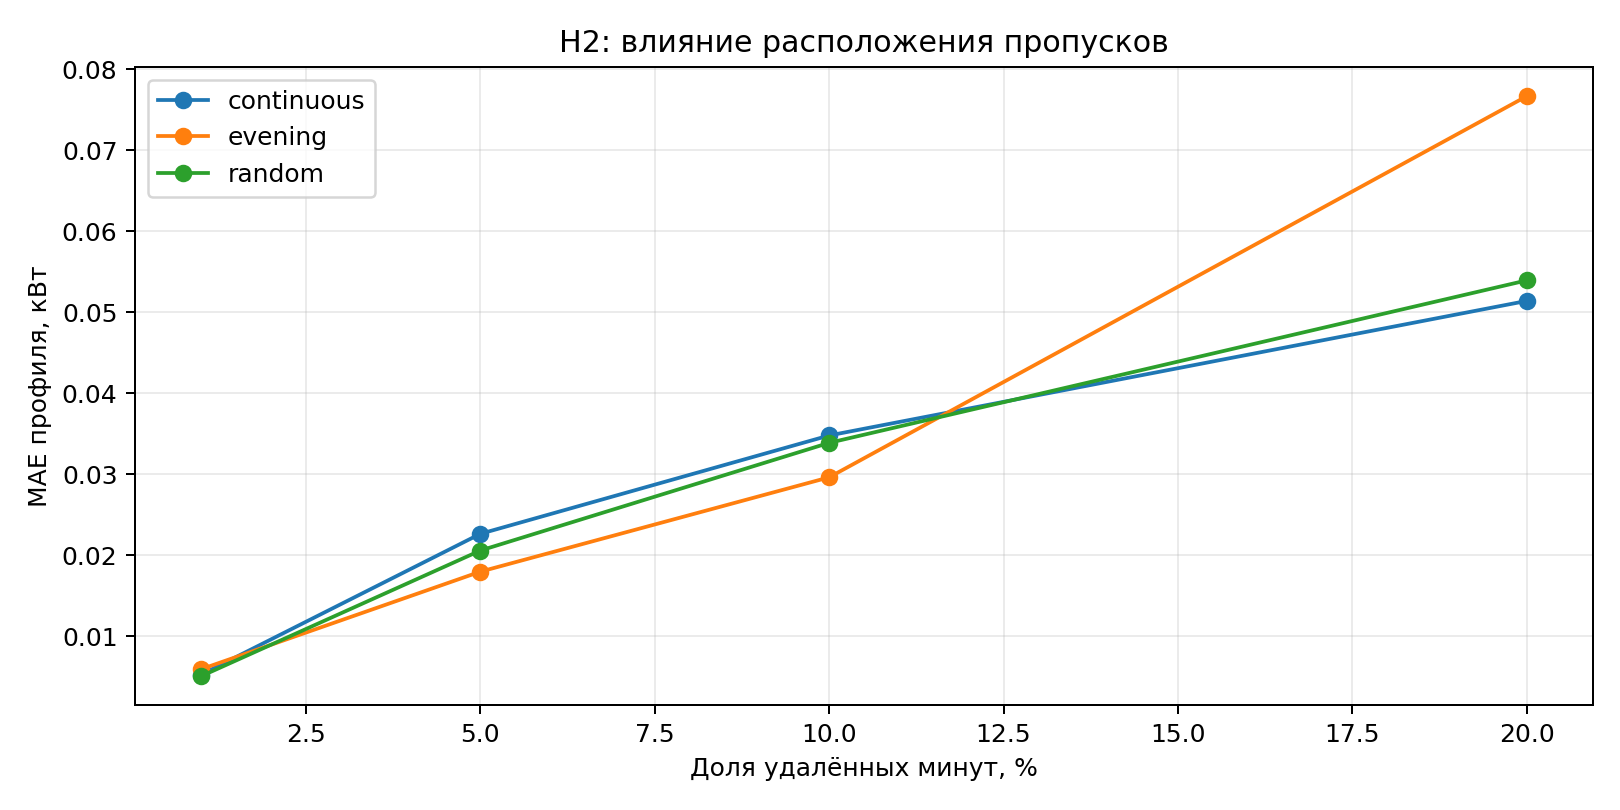

In [4]:
p = out / "06_h2_summary.csv"
if p.exists():
    display(pd.read_csv(p, sep=";"))
    display(Image(filename=str(out / "06_h2_missing.png")))

## 6.5. Проверка H3: разные длины пропусков

Сравниваем MAE усреднённого профиля, MAE на общей области определённости и среднюю ошибку **восстановленных индивидуальных минут**, которые были заранее скрыты для контрольного эксперимента. При `valid=0` метод неприменим, а не имеет нулевую ошибку.

06_h3_summary.csv


,scenario,method,experiments,valid,mean_mae_kw,mean_common_mae_kw,mean_rmse_kw,mean_coverage_pct,mean_energy_bias_pct,mean_imputed_mae_kw,mean_imputed_count,mean_imputed_coverage_pct,p025_mae_kw,p975_mae_kw
0,clustered_days,available,30,30,0.034930,0.034930,0.049680,100.0,0.132674,NaN,0.000000,NaN,0.030701,0.039031
1,clustered_days,complete_days,30,30,0.055017,0.055017,0.073758,100.0,0.233583,NaN,0.000000,NaN,0.044887,0.066278
2,clustered_days,linear_15,30,30,0.007729,0.007729,0.014682,100.0,0.020882,0.098307,4306.233333,99.681327,0.006642,0.008888
3,clustered_days,linear_60,30,30,0.007729,0.007729,0.014682,100.0,0.020882,0.098307,4306.233333,99.681327,0.006642,0.008888
4,continuous,available,30,30,0.035050,0.035050,0.047713,100.0,-0.022405,NaN,0.000000,NaN,0.031098,0.043943
5,continuous,complete_days,30,30,0.041595,0.041595,0.056619,100.0,-0.050680,NaN,0.000000,NaN,0.037232,0.046736
6,continuous,linear_15,30,30,0.035050,0.035050,0.047713,100.0,-0.022405,NaN,0.000000,0.000000,0.031098,0.043943
7,continuous,linear_60,30,30,0.035050,0.035050,0.047713,100.0,-0.022405,NaN,0.000000,0.000000,0.031098,0.043943
8,evening,available,30,30,0.029887,0.029887,0.077617,100.0,0.024467,NaN,0.000000,NaN,0.028017,0.032019
9,evening,complete_days,30,0,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN


06_h3_gap_summary.csv


,gap_length,method,experiments,valid,mean_mae_kw,mean_common_mae_kw,mean_rmse_kw,mean_coverage_pct,mean_energy_bias_pct,mean_imputed_mae_kw,mean_imputed_count,mean_imputed_coverage_pct,p025_mae_kw,p975_mae_kw
0,1,available,15,15,0.034156,0.034156,0.050791,100.0,-0.043337,NaN,0.000000,NaN,0.032655,0.035769
1,1,complete_days,15,0,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN
2,1,linear_15,15,15,0.005588,0.005588,0.011284,100.0,-0.027755,0.071200,4313.733333,99.854938,0.005298,0.005845
3,1,linear_60,15,15,0.005588,0.005588,0.011284,100.0,-0.027755,0.071200,4313.733333,99.854938,0.005298,0.005845
4,5,available,15,15,0.033420,0.033420,0.049292,100.0,0.007568,NaN,0.000000,NaN,0.031619,0.035324
5,5,complete_days,15,0,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN
6,5,linear_15,15,15,0.010673,0.010673,0.019677,100.0,-0.054849,0.144388,4300.000000,99.537037,0.009463,0.011659
7,5,linear_60,15,15,0.010616,0.010616,0.019601,100.0,-0.055400,0.144516,4312.000000,99.814815,0.009495,0.011659
8,15,available,15,15,0.033884,0.033884,0.049764,100.0,-0.022623,NaN,0.000000,NaN,0.030768,0.036596
9,15,complete_days,15,0,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN


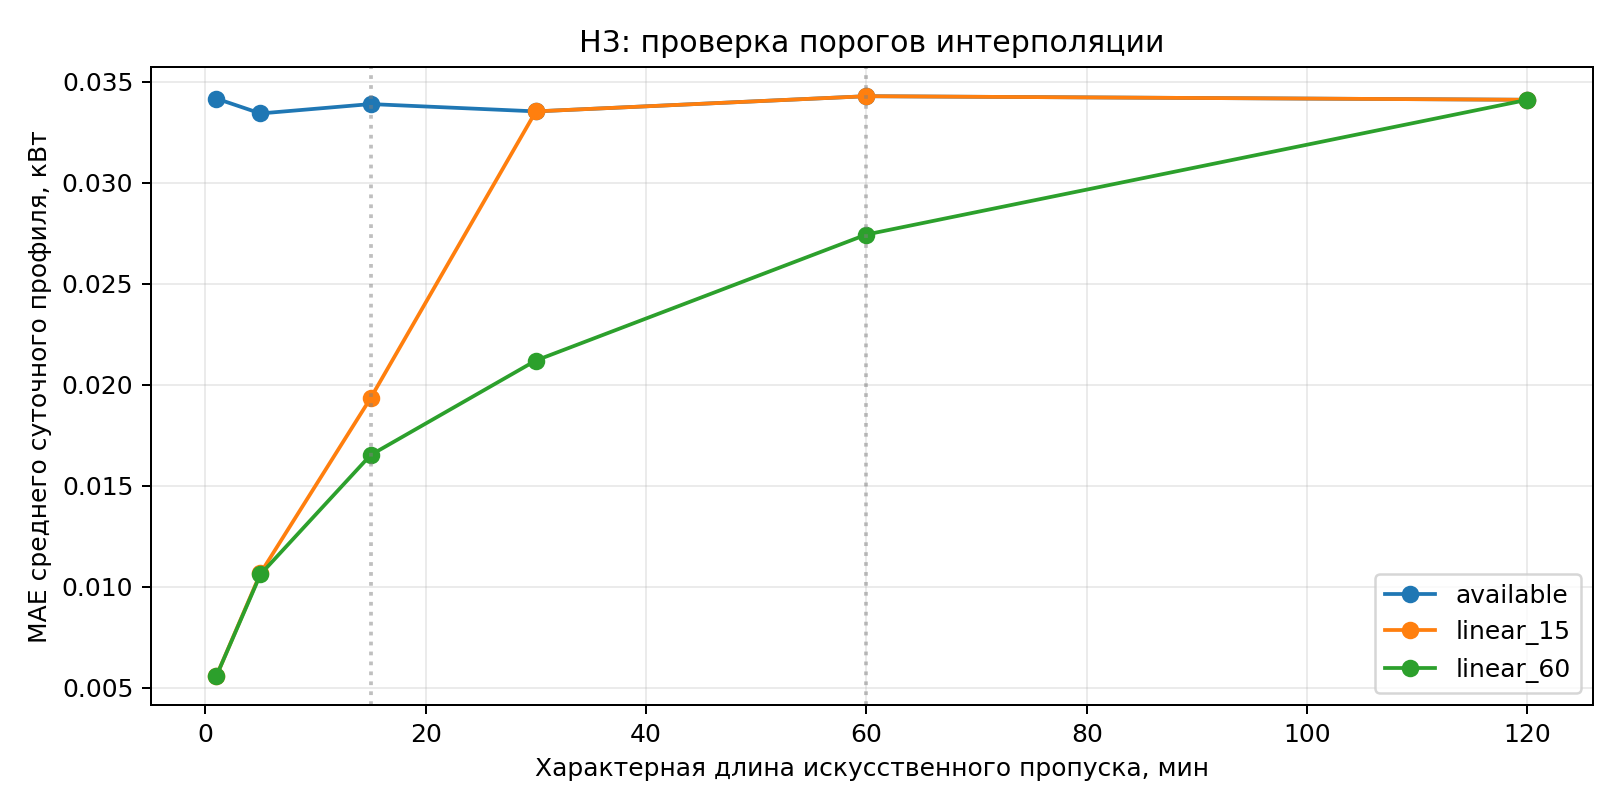

In [5]:
for filename in ("06_h3_summary.csv", "06_h3_gap_summary.csv"):
    p = out / filename
    if p.exists():
        print(filename)
        display(pd.read_csv(p, sep=";"))
if (out / "06_h3_gaps.png").exists():
    display(Image(filename=str(out / "06_h3_gaps.png")))

## 6.6. Физическая согласованность, временная зависимость, FFT

Энергия минуты: $E=P/60$ кВт·ч. Диагностика подсчётчиков в Вт·ч: $E_{other}=1000P/60-(E_1+E_2+E_3)$. Отрицательные остатки сохраняются и отмечаются, а не обнуляются. Автокорреляция среднесуточного ряда (лаги 1 и 7 суток) носит описательный характер. FFT среднего суточного профиля показывает **внутрисуточные гармоники**, не доказывая многолетнюю сезонность.

03_physics_consistency.csv


,status,valid_minutes,negative_residual_minutes,negative_residual_pct,median_residual_wh,mean_residual_wh,interpretation
0,ok,2049280,1050,0.051238,5.5,9.314693,Negative residual can reflect metering/roundin...


06_daily_dependence.csv


,lag_days,pairs,correlation
0,1,1290,0.615789
1,7,1271,0.546977


06_fft_mean_day.csv


,cycles_per_day,amplitude_kw
0,0.0,0.000000
1,1.0,0.205786
2,2.0,0.603807
3,3.0,0.182505
4,4.0,0.246676
5,5.0,0.183598
6,6.0,0.088700
7,7.0,0.077564
8,8.0,0.090268
9,9.0,0.087749


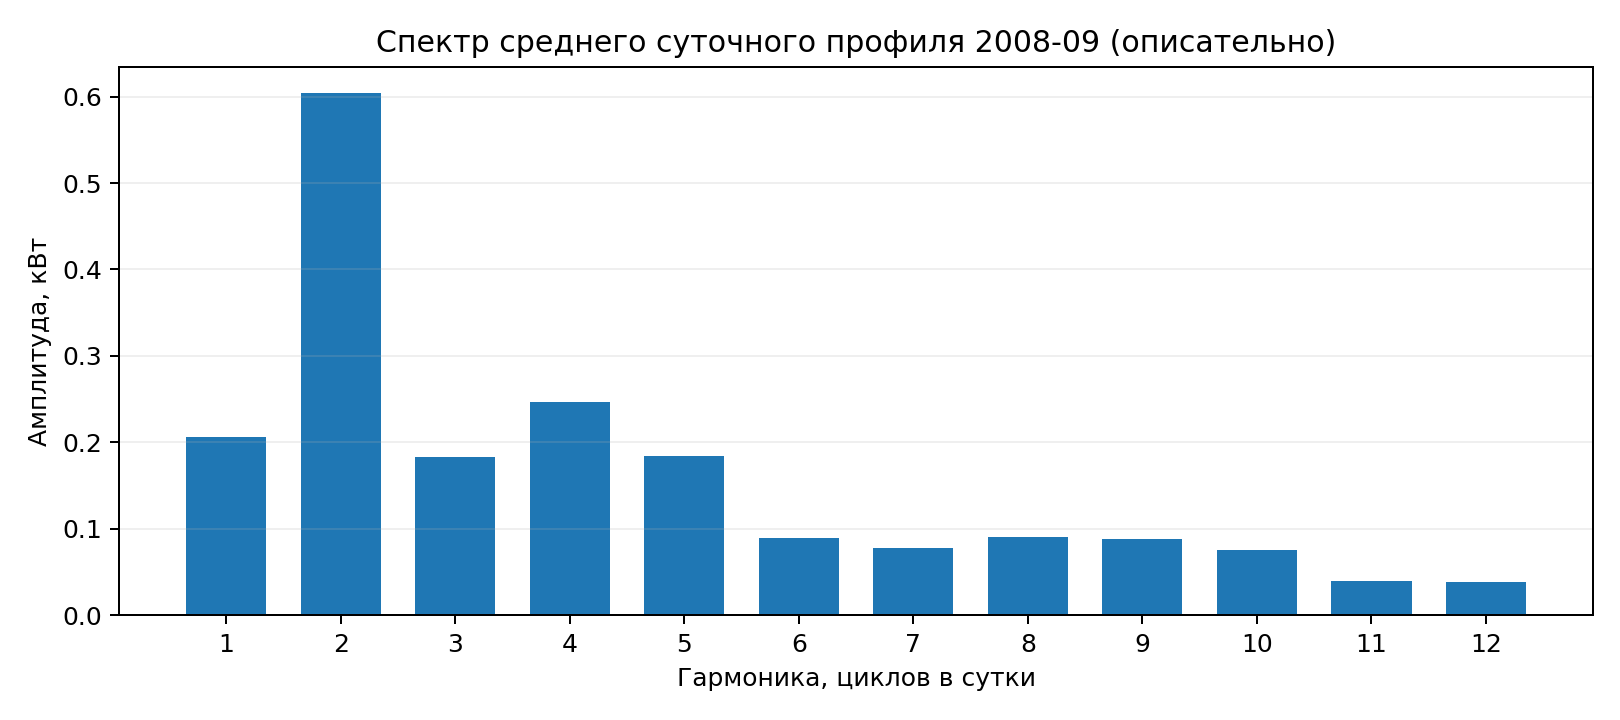

In [6]:
for filename in ("03_physics_consistency.csv", "06_daily_dependence.csv", "06_fft_mean_day.csv"):
    p = out / filename
    if p.exists():
        print(filename)
        display(pd.read_csv(p, sep=";").head(15))
if (out / "06_fft_mean_day.png").exists():
    display(Image(filename=str(out / "06_fft_mean_day.png")))

## 6.7. Проверка воспроизводимости

Создаём SHA-256 манифест файлов результата и сверяем сохранённые численные средние с независимой группировкой строк экспериментов. Такая арифметическая проверка **не доказывает** статистические предпосылки. Отчёт следует обновлять числами только после полного выполнения этой версии на исходном UCI.

In [7]:
from run_research import hash_file
import json
import platform
from datetime import datetime, timezone
import numpy as np

metadata = {"source": str(source), "source_sha256": hash_file(source),
            "generated_utc": datetime.now(timezone.utc).isoformat(),
            "python": platform.python_version(), "pandas": pd.__version__,
            "numpy": np.__version__,
            "science_code_sha256": hash_file(root / "ipd_science.py")}
(out / "provenance.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2)+"\n", encoding="utf-8")
manifest = write_manifest(out)
print("Контрольные суммы:", manifest)
print("Независимая арифметическая проверка:", verify_directory(out))

Контрольные суммы: /content/ipd/результаты/household_power_consumption-b916e64b/этап_06_v2/manifest_sha256.json
Независимая арифметическая проверка: {'06_h2_summary.csv': 'verified', '06_h3_summary.csv': 'verified', '06_h3_gap_summary.csv': 'verified'}
